# Кросс-валидация, подбор гиперпараметров и сравнение моделей
Цель: Научиться использовать кросс-валидацию для честной оценки, автоматизировать подбор гиперпараметров с помощью GridSearchCV и сравнить разные модели (от логистической регрессии до бустинга) на одном датасете.
Датасет: Breast Cancer. Бинарная классификация (злокачественная / доброкачественная).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, roc_curve, classification_report, confusion_matrix

# Модели
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

import warnings
warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")

In [2]:
# Загружаем данные
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target # 0 - злокачественная, 1 - доброкачественная

# Сплит
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Train: {X_train.shape}, Test: {X_test.shape}")
print(f"Доля миноритарного класса в Train: {np.mean(y_train == 0):.2%}")

Train: (455, 30), Test: (114, 30)
Доля миноритарного класса в Train: 37.36%


На прошлом семинаре мы делили данные один раз. Но если random_state окажется неудачным, мы можем получить искаженную оценку.
Кросс-валидация (K-Fold) разбивает Train на K частей и обучает модель K раз, оценивая на разных кусках.
Сравним LogisticRegression на одном сплите и на 5-фолдовой кросс-валидации.

In [3]:
# Пайплайн (масштабирование + логистическая регрессия)
pipe_lr = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(max_iter=1000, random_state=42))
])

# Оценка на одном тестовом сплите (как в прошлый раз)
pipe_lr.fit(X_train, y_train)
single_score = pipe_lr.score(X_test, y_test)
print(f"Оценка на одном сплите (Accuracy): {single_score:.4f}")

# Оценка через кросс-валидацию на Train
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(pipe_lr, X_train, y_train, cv=cv, scoring='accuracy')
print(f"Кросс-валидация (Accuracy): {cv_scores.mean():.4f} +/- {cv_scores.std():.4f}")

Оценка на одном сплите (Accuracy): 0.9825
Кросс-валидация (Accuracy): 0.9780 +/- 0.0098


### Автоматический подбор гиперпараметров (GridSearchCV)
В первом ноутбуке мы вручную меняли max_depth и n_estimators у Random Forest. Это долго.
GridSearchCV переберет все комбинации параметров, которые мы укажем, и выберет лучшую по кросс-валидации.

In [4]:
# Задаем сетку параметров
param_grid_rf = {
    'clf__n_estimators': [50, 100, 200],       # Число деревьев
    'clf__max_depth': [None, 5, 10],           # Глубина
    'clf__min_samples_leaf': [1, 2, 4]         # Мин. объектов в листе
}

# Пайплайн
pipe_rf = Pipeline([
    ('scaler', StandardScaler()), # Лесу скейлер не нужен, но для единообразия пайплайна оставим (не навредит)
    ('clf', RandomForestClassifier(class_weight='balanced', random_state=42))
])

# GridSearchCV (считаем ROC-AUC, т.к. она лучше отражает качество при дисбалансе)
grid_search = GridSearchCV(
    pipe_rf, param_grid_rf, cv=cv, scoring='roc_auc', n_jobs=-1, verbose=1
)
grid_search.fit(X_train, y_train)

print(f"Лучшие параметры: {grid_search.best_params_}")
print(f"Лучший ROC-AUC на CV: {grid_search.best_score_:.4f}")

Fitting 5 folds for each of 27 candidates, totalling 135 fits
Лучшие параметры: {'clf__max_depth': None, 'clf__min_samples_leaf': 2, 'clf__n_estimators': 50}
Лучший ROC-AUC на CV: 0.9918


### Линейные модели vs Метрические vs Ансамбли

Сравним 5 алгоритмов на кросс-валидации:
- Logistic Regression (линейный базлайн).
- kNN (метрический, чувствителен к масштабу).
- SVM (максимальная разделяющая полоса).
- Random Forest (бэггинг).
- HistGradientBoosting (бустинг).

In [5]:
# Словарь с моделями (все обернуты в Pipeline со StandardScaler)
models = {
    "Logistic Regression": Pipeline([('sc', StandardScaler()), ('clf', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42))]),
    "kNN (k=5)": Pipeline([('sc', StandardScaler()), ('clf', KNeighborsClassifier(n_neighbors=5))]),
    "SVM (RBF)": Pipeline([('sc', StandardScaler()), ('clf', SVC(kernel='rbf', class_weight='balanced', probability=True, random_state=42))]),
    "Random Forest": Pipeline([('sc', StandardScaler()), ('clf', RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42))]),
    "HistGradientBoosting": Pipeline([('sc', StandardScaler()), ('clf', HistGradientBoostingClassifier(random_state=42))])
}

results = []

for name, model in models.items():
    # Считаем accuracy и roc-auc на кросс-валидации
    acc_scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='accuracy')
    auc_scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='roc_auc')
    
    results.append({
        "Модель": name,
        "Accuracy (CV)": f"{acc_scores.mean():.3f} +/- {acc_scores.std():.3f}",
        "ROC-AUC (CV)": f"{auc_scores.mean():.3f} +/- {auc_scores.std():.3f}"
    })

# Вывод в красивую табличку
df_results = pd.DataFrame(results)
display(df_results)

,Модель,Accuracy (CV),ROC-AUC (CV)
0,Logistic Regression,0.976 +/- 0.013,0.996 +/- 0.005
1,kNN (k=5),0.963 +/- 0.011,0.988 +/- 0.008
2,SVM (RBF),0.974 +/- 0.011,0.996 +/- 0.004
3,Random Forest,0.960 +/- 0.011,0.991 +/- 0.005
4,HistGradientBoosting,0.963 +/- 0.015,0.994 +/- 0.003


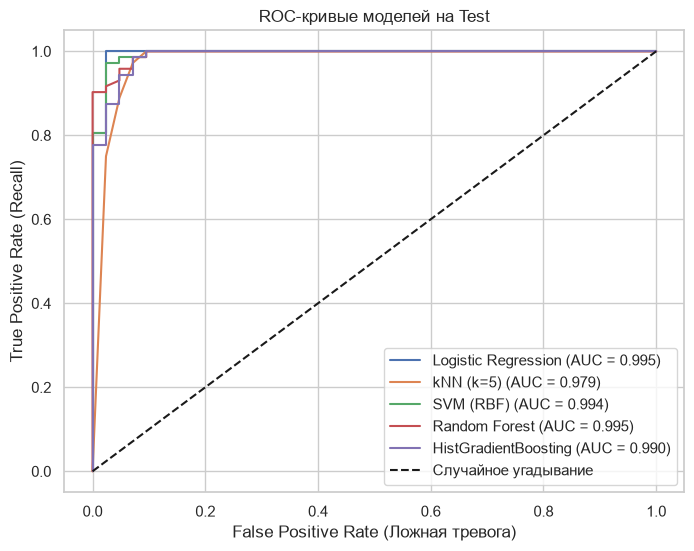

In [6]:
plt.figure(figsize=(8, 6))

for name, model in models.items():
    model.fit(X_train, y_train)
    
    # Получаем вероятности положительного класса
    y_probs = model.predict_proba(X_test)[:, 1]
    
    # Считаем FPR, TPR и AUC
    fpr, tpr, _ = roc_curve(y_test, y_probs)
    auc = roc_auc_score(y_test, y_probs)
    
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], 'k--', label="Случайное угадывание")
plt.xlabel("False Positive Rate (Ложная тревога)")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC-кривые моделей на Test")
plt.legend(loc="lower right")
plt.show()

### Настройка порога классификации

По умолчанию predict() использует порог 0.5. В медицине (рак груди) пропустить злокачественную опухоль (False Negative) страшнее, чем ошибочно назначить обследование здоровому (False Positive).
Поэтому мы понизим порог для лучшей модели, чтобы повысить Recall (полноту) для класса 0 (злокачественная).

In [7]:
# Берем лучшую модель (например, HistGradientBoosting)
best_model = models["HistGradientBoosting"]
best_model.fit(X_train, y_train)

# Получаем вероятности принадлежности к классу 0 (Злокачественная)
y_probs_class0 = best_model.predict_proba(X_test)[:, 0]

# Стандартный порог (0.5)
y_pred_default = (y_probs_class0 > 0.5).astype(int)

# Новый порог (0.3) - если вероятность рака > 30%, отправляем на доп. обследование
y_pred_lowered = (y_probs_class0 > 0.3).astype(int)

print("=== СТАНДАРТНЫЙ ПОРОГ (0.5) ===")
print(classification_report(y_test, y_pred_default, target_names=['Злокачественная', 'Доброкачественная']))

print("\n=== ПОНИЖЕННЫЙ ПОРОГ (0.3) ===")
print(classification_report(y_test, y_pred_lowered, target_names=['Злокачественная', 'Доброкачественная']))

=== СТАНДАРТНЫЙ ПОРОГ (0.5) ===
                   precision    recall  f1-score   support

  Злокачественная       0.05      0.10      0.07        42
Доброкачественная       0.03      0.01      0.02        72

         accuracy                           0.04       114
        macro avg       0.04      0.05      0.04       114
     weighted avg       0.04      0.04      0.04       114


=== ПОНИЖЕННЫЙ ПОРОГ (0.3) ===
                   precision    recall  f1-score   support

  Злокачественная       0.04      0.07      0.05        42
Доброкачественная       0.05      0.03      0.04        72

         accuracy                           0.04       114
        macro avg       0.04      0.05      0.04       114
     weighted avg       0.05      0.04      0.04       114



### Важность признаков (Feature Importance)

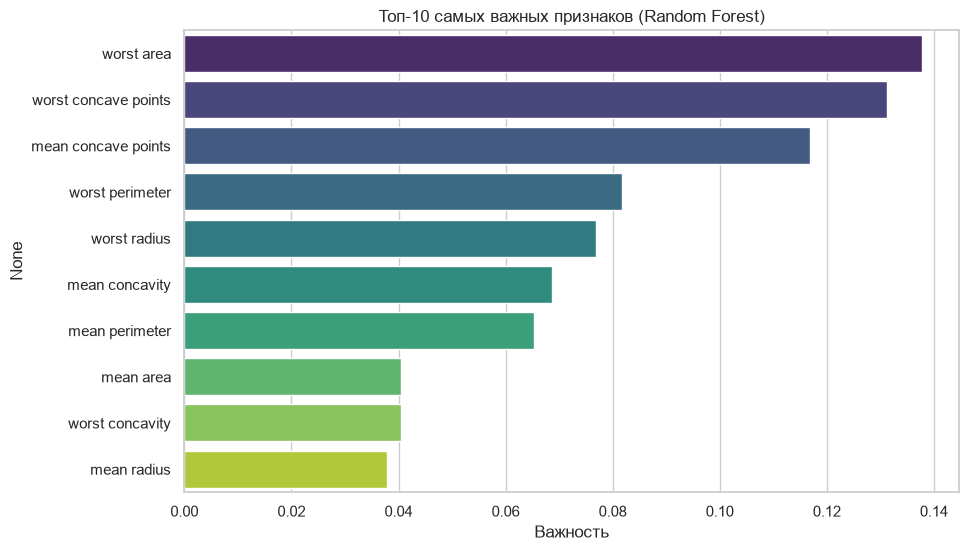

In [8]:
# Достаем обученный Random Forest из пайплайна
rf_model = models["Random Forest"].named_steps['clf']

# Создаем DataFrame с важностями
importances = pd.Series(rf_model.feature_importances_, index=X.columns)
top_10 = importances.sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_10.values, y=top_10.index, palette="viridis")
plt.title("Топ-10 самых важных признаков (Random Forest)")
plt.xlabel("Важность")
plt.show()